# TravelTide — Exploratory Data Analysis

Explore the selected users’ behavior and assess data quality as a basis
for customer segmentation and reward recommendations.

Das Verhalten der ausgewählten Nutzer untersuchen und die Datenqualität
als Grundlage für Kundengruppen und Reward-Empfehlungen prüfen.

## 1. Packages / Pakete

Import packages for data analysis, visualization and later clustering.
Display the Python environment used by this notebook.

Pakete für Datenanalyse, Visualisierung und späteres Clustering importieren.
Die verwendete Python-Umgebung anzeigen.

In [48]:
# packages for data analysis, visualization and later clustering
# pakete für datenanalyse, visualisierung und späteres clustering

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from IPython.display import HTML, display

# shared color palette and chart defaults
# gemeinsame farbpalette und standardgestaltung der diagramme
COLORS = {
    "blue": "#93B4DB",
    "lavender": "#B5ACD9",
    "mint": "#9BCBC3",
    "ice": "#B9DDE8",
    "highlight": "#8D83BA",
    "text": "#334155",
    "background": "#F5F7FB",
}

PALETTE = [
    COLORS["blue"],
    COLORS["lavender"],
    COLORS["mint"],
    COLORS["ice"],
]

sns.set_theme(
    style="whitegrid",
    palette=PALETTE,
    rc={
        "figure.facecolor": COLORS["background"],
        "axes.facecolor": COLORS["background"],
        "text.color": COLORS["text"],
        "axes.labelcolor": COLORS["text"],
        "xtick.color": COLORS["text"],
        "ytick.color": COLORS["text"],
        "grid.color": "#DDE3EC",
        "axes.spines.top": False,
        "axes.spines.right": False,
    },
)

px.defaults.template = "plotly_white"
px.defaults.color_discrete_sequence = PALETTE

print("Python environment / Python-Umgebung:", sys.executable)

Python environment / Python-Umgebung: c:\Users\mpero\Desktop\GitHub\TravelTide\.venv\Scripts\python.exe


## 2. Load and validate data / Daten laden und prüfen

### 2.1 Load sessions / Sessions laden

Determine the project folder and load the local session export.
Check the number of sessions and distinct users.

Den Projektordner bestimmen und den lokalen Session-Export laden.
Die Anzahl der Sessions und unterschiedlichen Nutzer prüfen.

In [49]:
# locate the project folder from either the root or notebooks directory
# projektordner vom hauptordner oder notebook-ordner aus bestimmen
project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent

# load the local session export
# lokalen session-export laden
sessions = pd.read_csv(project_root / "data" / "raw" / "sessions.csv")

print("Sessions:", len(sessions))
print("Users / Nutzer:", sessions["user_id"].nunique())

Sessions: 49211
Users / Nutzer: 5998


### 2.2 Load remaining tables and validate exports
### Weitere Tabellen laden und Exporte prüfen

Load user, flight and hotel data. Compare all four table sizes with
the SQL results and check primary keys for missing and duplicate values.

Nutzer-, Flug- und Hoteldaten laden. Die Größe aller vier Tabellen mit
den SQL-Ergebnissen vergleichen und Primärschlüssel auf fehlende
und doppelte Werte prüfen.

In [50]:
# load the remaining local exports
# weitere lokale exportdateien laden
users = pd.read_csv(project_root / "data" / "raw" / "users.csv")
flights = pd.read_csv(project_root / "data" / "raw" / "flights.csv")
hotels = pd.read_csv(project_root / "data" / "raw" / "hotels.csv")

# compare exported row counts with SQL results and check primary keys
# exportierte zeilenzahlen mit SQL-ergebnissen vergleichen und schlüssel prüfen
tables = {
    "users": (users, "user_id", 5998),
    "sessions": (sessions, "session_id", 49211),
    "flights": (flights, "trip_id", 13717),
    "hotels": (hotels, "trip_id", 14313),
}

export_checks = pd.DataFrame([
    {
        "table": name,
        "rows": len(df),
        "expected_rows": expected,
        "row_count_matches": len(df) == expected,
        "missing_keys": df[key].isna().sum(),
        "duplicate_keys": df[key].duplicated().sum(),
    }
    for name, (df, key, expected) in tables.items()
])

# highlight validation results while keeping the shared table design
# prüfergebnisse hervorheben und gemeinsame tabellengestaltung verwenden
def highlight_check(value, expected):
    passed = value == expected
    background = "#DDEFEA" if passed else "#F5DFE3"
    color = "#24594D" if passed else "#8B3045"

    return (
        f"background-color: {background}; "
        f"color: {color}; font-weight: 600;"
    )


styled_checks = (
    style_overview(
        export_checks,
        "Export validation",
        {
            "rows": "{:,.0f}",
            "expected_rows": "{:,.0f}",
            "row_count_matches": (
                lambda value: "✓ OK" if value else "✗ Mismatch"
            ),
            "missing_keys": "{:,.0f}",
            "duplicate_keys": "{:,.0f}",
        },
    )
    .map(
        lambda value: highlight_check(value, True),
        subset=["row_count_matches"],
    )
    .map(
        lambda value: highlight_check(value, 0),
        subset=["missing_keys", "duplicate_keys"],
    )
)

display(styled_checks)

table,rows,expected_rows,row_count_matches,missing_keys,duplicate_keys
users,"5,998","5,998",✓ OK,0,0
sessions,"49,211","49,211",✓ OK,0,0
flights,"13,717","13,717",✓ OK,0,0
hotels,"14,313","14,313",✓ OK,0,0


### Findings / Erkenntnisse

All four exported row counts match the SQL results.
The primary keys contain no missing or duplicate values.

Alle vier exportierten Zeilenzahlen stimmen mit den SQL-Ergebnissen überein.
Die Primärschlüssel enthalten keine fehlenden oder doppelten Werte.

In [51]:
# create working copies and preserve the imported source data
# arbeitskopien erstellen und eingelesene ausgangsdaten erhalten
users_work = users.copy()
sessions_work = sessions.copy()
flights_work = flights.copy()
hotels_work = hotels.copy()

working_tables = {
    "users": users_work,
    "sessions": sessions_work,
    "flights": flights_work,
    "hotels": hotels_work,
}

## 3. Data types and missing values
## Datentypen und fehlende Werte

Inspect the imported data types and missing values in each column.
CSV files do not preserve database types, so dates and other fields
may require explicit conversion.

Die eingelesenen Datentypen und fehlenden Werte jeder Spalte prüfen.
CSV-Dateien bewahren die Datenbanktypen nicht. Datumsfelder und andere
Spalten müssen deshalb gegebenenfalls ausdrücklich umgewandelt werden.

In [52]:
# shared pastel styling for overview tables
# gemeinsame pastellgestaltung für übersichtstabellen
def style_overview(df, title, formats=None):
    return (
        df.style
        .hide(axis="index")
        .set_caption(title)
        .format(formats or {})
        .set_table_styles([
            {
                "selector": "caption",
                "props": [
                    ("color", COLORS["ice"]),
                    ("font-size", "18px"),
                    ("font-weight", "700"),
                    ("text-align", "left"),
                    ("padding", "12px 0"),
                ],
            },
            {
                "selector": "th",
                "props": [
                    ("background-color", COLORS["blue"]),
                    ("color", COLORS["text"]),
                    ("padding", "10px 14px"),
                    ("text-align", "left"),
                ],
            },
            {
                "selector": "td",
                "props": [
                    ("background-color", COLORS["background"]),
                    ("color", COLORS["text"]),
                    ("padding", "8px 14px"),
                    ("border-bottom", "1px solid #DDE3EC"),
                ],
            },
            {
                "selector": "table",
                "props": [
                    ("border-collapse", "collapse"),
                    ("font-family", "Segoe UI, sans-serif"),
                ],
            },
        ])
    )
    return styled.format(formats or {})


# inspect each table without changing its values
# jede tabelle prüfen, ohne ihre werte zu verändern
for name, df in working_tables.items():
    overview = pd.DataFrame({
        "column": df.columns,
        "dtype": df.dtypes.astype(str).to_numpy(),
        "missing": df.isna().sum().to_numpy(),
        "missing_pct": df.isna().mean().mul(100).to_numpy(),
    })

    display(style_overview(
        overview,
        f"{name} — Data overview",
        {
            "missing": "{:,.0f}",
            "missing_pct": "{:.2f}%",
        },
    ))

column,dtype,missing,missing_pct
user_id,int64,0,0.00%
birthdate,str,0,0.00%
gender,str,0,0.00%
married,bool,0,0.00%
has_children,bool,0,0.00%
home_country,str,0,0.00%
home_city,str,0,0.00%
home_airport,str,0,0.00%
home_airport_lat,float64,0,0.00%
home_airport_lon,float64,0,0.00%


column,dtype,missing,missing_pct
session_id,str,0,0.00%
user_id,int64,0,0.00%
trip_id,str,"32,509",66.06%
session_start,str,0,0.00%
session_end,str,0,0.00%
flight_discount,bool,0,0.00%
hotel_discount,bool,0,0.00%
flight_discount_amount,float64,"40,929",83.17%
hotel_discount_amount,float64,"43,006",87.39%
flight_booked,bool,0,0.00%


column,dtype,missing,missing_pct
trip_id,str,0,0.00%
origin_airport,str,0,0.00%
destination,str,0,0.00%
destination_airport,str,0,0.00%
seats,int64,0,0.00%
return_flight_booked,bool,0,0.00%
departure_time,str,0,0.00%
return_time,str,597,4.35%
checked_bags,int64,0,0.00%
trip_airline,str,0,0.00%


column,dtype,missing,missing_pct
trip_id,str,0,0.00%
hotel_name,str,0,0.00%
nights,int64,0,0.00%
rooms,int64,0,0.00%
check_in_time,str,0,0.00%
check_out_time,str,0,0.00%
hotel_per_room_usd,int64,0,0.00%


### 3.1 Convert user dates / Nutzerdaten in Datumswerte umwandeln

Convert birthdate and sign_up_date to datetime values.
Count any previously non-missing values that cannot be parsed.

birthdate und sign_up_date in Datumswerte umwandeln.
Zählen, wie viele zuvor vorhandene Werte nicht gelesen werden können.

In [53]:
# convert date columns and check for parsing failures
# datumsspalten umwandeln und auf nicht lesbare werte prüfen
date_checks = []

for column in ["birthdate", "sign_up_date"]:
    original = users_work[column].copy()
    converted = pd.to_datetime(original, errors="coerce")

    date_checks.append({
        "column": column,
        "dtype_before": str(original.dtype),
        "dtype_after": str(converted.dtype),
        "parsing_failures": (
            original.notna() & converted.isna()
        ).sum(),
    })

    users_work[column] = converted

display(style_overview(
    pd.DataFrame(date_checks),
    "users — Date conversion",
    {"parsing_failures": "{:,.0f}"},
))

column,dtype_before,dtype_after,parsing_failures
birthdate,str,datetime64[us],0
sign_up_date,str,datetime64[us],0


### 3.2 Validate user categories / Nutzerkategorien prüfen

Inspect gender, marital status and whether users have children.
has_children indicates whether children are present, not their number.

Geschlecht, Familienstand und die Angabe zu Kindern untersuchen.
has_children zeigt, ob Nutzer Kinder haben, nicht wie viele.

value,users,share_pct
F,"5,292",88.23%
M,695,11.59%
O,11,0.18%
value,users,share_pct
False,"3,356",55.95%
True,"2,642",44.05%
value,users,share_pct
False,"4,040",67.36%
True,"1,958",32.64%


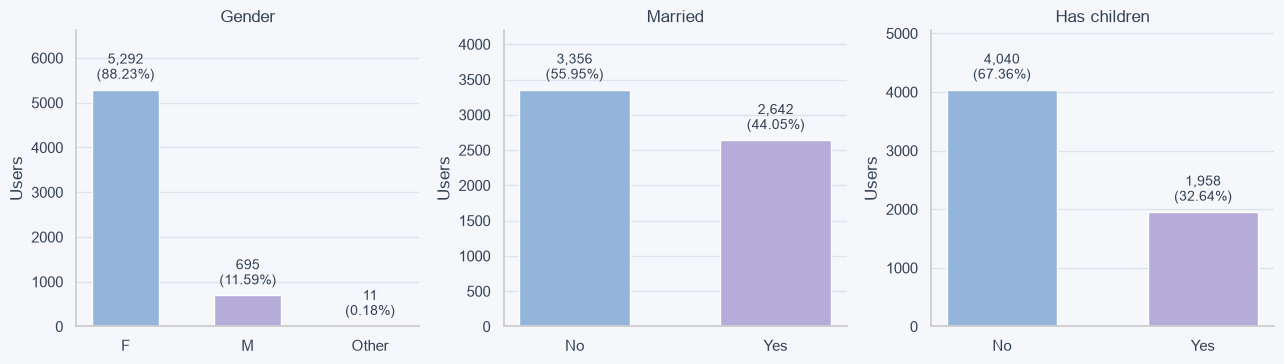

In [54]:
# prepare category tables and charts
# kategorietabellen und diagramme vorbereiten
chart_settings = [
    ("gender", ["F", "M", "O"], ["F", "M", "Other"], "Gender"),
    ("married", [False, True], ["No", "Yes"], "Married"),
    ("has_children", [False, True], ["No", "Yes"], "Has children"),
]

html_tables = []

for column, order, labels, title in chart_settings:
    counts = (
        users_work[column]
        .value_counts(dropna=False)
        .rename_axis("value")
        .reset_index(name="users")
    )
    counts["share_pct"] = counts["users"] / len(users_work) * 100

    styled = style_overview(
        counts,
        title,
        {
            "users": "{:,.0f}",
            "share_pct": "{:.2f}%",
        },
    )

    # apply the shared pastel palette to table headers
    # gemeinsame pastellpalette für tabellenüberschriften verwenden
    styled = styled.set_table_styles([
        {
            "selector": "th",
            "props": [
                ("background-color", COLORS["blue"]),
                ("color", COLORS["text"]),
            ],
        },
      {
    "selector": "caption",
    "props": [
        ("color", COLORS["ice"]),
        ("font-size", "18px"),
        ("font-weight", "700"),
    ],
},
        {
            "selector": "td",
            "props": [
                ("background-color", COLORS["background"]),
                ("color", COLORS["text"]),
            ],
        },
    ], overwrite=False)

    html_tables.append(
        f'<div style="min-width: 0;">{styled.to_html()}</div>'
    )

# display three tables in one row
# drei tabellen in einer zeile anzeigen
display(HTML(
    '<div style="display: grid; '
    'grid-template-columns: repeat(3, minmax(0, 1fr)); '
    'gap: 24px; overflow-x: auto;">'
    + "".join(html_tables)
    + "</div>"
))

# display three charts underneath in the same order
# drei diagramme darunter in derselben reihenfolge anzeigen
fig, axes = plt.subplots(ncols=3, figsize=(13, 3.8))

for ax, (column, order, labels, title) in zip(axes, chart_settings):
    counts = (
        users_work[column]
        .value_counts()
        .reindex(order, fill_value=0)
    )
    percentages = counts / len(users_work) * 100

    bars = ax.bar(
        labels,
        counts.to_numpy(),
        color=PALETTE[:len(order)],
        width=0.55,
    )

    ax.bar_label(
        bars,
        labels=[
            f"{count:,.0f}\n({percentage:.2f}%)"
            for count, percentage in zip(counts, percentages)
        ],
        padding=5,
        fontsize=10,
    )

    ax.set(
        title=title,
        ylabel="Users",
        ylim=(0, max(counts.max(), 1) * 1.25),
    )
    ax.grid(axis="x", visible=False)

plt.tight_layout()
plt.show()

### 3.3 Validate text values / Textwerte prüfen

Check all user text columns for empty values, surrounding whitespace
and variants that differ only in capitalization or whitespace.

Alle Textspalten auf leere Werte, äußere Leerzeichen und Varianten prüfen,
die sich nur durch Groß-/Kleinschreibung oder Leerzeichen unterscheiden.

In [55]:
# inspect text columns without changing the working data
# textspalten prüfen, ohne die arbeitsdaten zu verändern
text_checks = []
text_variants = {}

for column in users_work.select_dtypes(
    include=["object", "string", "str"]
).columns:
    values = users_work[column].astype("string")
    stripped = values.str.strip()
    normalized = stripped.str.casefold()

    variants = pd.DataFrame({
        "original": values,
        "normalized": normalized,
    }).dropna().drop_duplicates()

    variant_counts = variants.groupby("normalized")["original"].nunique()
    variant_groups = variant_counts[variant_counts > 1].index

    text_checks.append({
        "column": column,
        "unique_values": values.nunique(),
        "blank_values": stripped.eq("").sum(),
        "surrounding_whitespace": values.ne(stripped).sum(),
        "variant_groups": len(variant_groups),
    })

    text_variants[column] = variants[
        variants["normalized"].isin(variant_groups)
    ].sort_values(["normalized", "original"])

display(style_overview(
    pd.DataFrame(text_checks),
    "users — Text validation",
    {
        "unique_values": "{:,.0f}",
        "blank_values": "{:,.0f}",
        "surrounding_whitespace": "{:,.0f}",
        "variant_groups": "{:,.0f}",
    },
))

column,unique_values,blank_values,surrounding_whitespace,variant_groups
gender,3,0,0,0
home_country,2,0,0,0
home_city,105,0,0,0
home_airport,159,0,0,0


### 3.4 Validate user dates / Datumsangaben prüfen

Use the latest observed session date as the reference date.
Check birthdates and sign-up dates for chronological inconsistencies.

Das Datum der letzten beobachteten Session als Stichtag verwenden.
Geburts- und Anmeldedaten auf zeitliche Widersprüche prüfen.

In [56]:
# derive the reference date from the session data
# stichtag aus den session-daten ableiten
reference_date = pd.to_datetime(
    sessions_work["session_start"], errors="raise"
).max().normalize()

# check chronological consistency without removing records
# zeitliche plausibilität prüfen, ohne datensätze zu entfernen
date_validation = pd.DataFrame([
    {
        "check": "Birthdate after reference date",
        "affected_users": (
            users_work["birthdate"] > reference_date
        ).sum(),
    },
    {
        "check": "Sign-up before birthdate",
        "affected_users": (
            users_work["sign_up_date"] < users_work["birthdate"]
        ).sum(),
    },
    {
        "check": "Sign-up after reference date",
        "affected_users": (
            users_work["sign_up_date"] > reference_date
        ).sum(),
    },
])

print("Reference date:", reference_date.date())

display(style_overview(
    date_validation,
    "users — Date plausibility",
    {"affected_users": "{:,.0f}"},
))

Reference date: 2023-07-28


check,affected_users
Birthdate after reference date,0
Sign-up before birthdate,0
Sign-up after reference date,0


### 3.5 Calculate age / Alter berechnen

Calculate completed years of age at the reference date.
Inspect the age range and birth-year distribution, especially 2006.

Das Alter in vollendeten Jahren am Stichtag berechnen.
Altersspanne und Geburtsjahrverteilung untersuchen, insbesondere 2006.

metric,age
Minimum,16.0
Median,41.0
Mean,40.9
Maximum,88.0


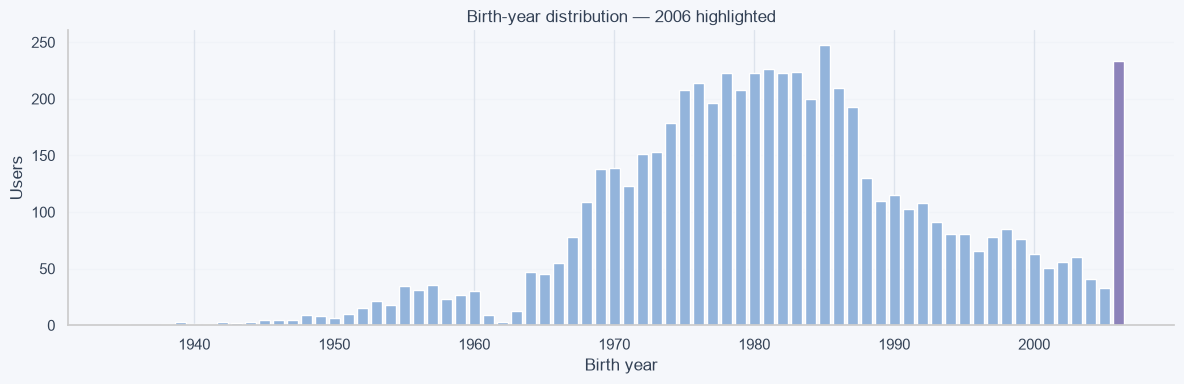

In [57]:
# subtract one year if the birthday has not yet occurred this year
# ein jahr abziehen, falls der geburtstag dieses jahr noch bevorsteht
birthdates = users_work["birthdate"]

birthday_pending = (
    (birthdates.dt.month > reference_date.month)
    | (
        (birthdates.dt.month == reference_date.month)
        & (birthdates.dt.day > reference_date.day)
    )
)

users_work["age"] = (
    reference_date.year
    - birthdates.dt.year
    - birthday_pending.astype(int)
).astype("Int64")

age_summary = pd.DataFrame({
    "metric": ["Minimum", "Median", "Mean", "Maximum"],
    "age": [
        users_work["age"].min(),
        users_work["age"].median(),
        users_work["age"].mean(),
        users_work["age"].max(),
    ],
})

display(style_overview(
    age_summary,
    "users — Age at reference date",
    {"age": "{:.1f}"},
))

birth_year_counts = (
    birthdates.dt.year
    .value_counts()
    .sort_index()
    .rename_axis("birth_year")
    .reset_index(name="users")
)

fig, ax = plt.subplots(figsize=(12, 4))
colors = [
    COLORS["highlight"] if year == 2006 else COLORS["blue"]
    for year in birth_year_counts["birth_year"]
]

ax.bar(
    birth_year_counts["birth_year"],
    birth_year_counts["users"],
    color=colors,
)
ax.set(
    title="Birth-year distribution — 2006 highlighted",
    xlabel="Birth year",
    ylabel="Users",
)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()